In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Inline indicates graphs should be presented as a cell output
%matplotlib

Using matplotlib backend: module://matplotlib_inline.backend_inline


In [2]:
# Load data
car_data = pd.read_csv('Cars93.csv', index_col=0, keep_default_na=False)
# keep_default_na as False ensures that pandas does not intepret the None string in the Airbag column as NaN

In [3]:
# Explore the data
# Get column names
car_data.columns

Index(['Manufacturer', 'Model', 'Type', 'Min.Price', 'Price', 'Max.Price',
       'MPG.city', 'MPG.highway', 'AirBags', 'DriveTrain', 'Cylinders',
       'EngineSize', 'Horsepower', 'RPM', 'Rev.per.mile', 'Man.trans.avail',
       'Fuel.tank.capacity', 'Passengers', 'Length', 'Wheelbase', 'Width',
       'Turn.circle', 'Rear.seat.room', 'Luggage.room', 'Weight', 'Origin',
       'Make'],
      dtype='str')

In [4]:
# Get a random sample of data
car_data.sample(5)

,Manufacturer,Model,Type,Min.Price,Price,Max.Price,MPG.city,MPG.highway,AirBags,DriveTrain,...,Passengers,Length,Wheelbase,Width,Turn.circle,Rear.seat.room,Luggage.room,Weight,Origin,Make
39,Geo,Metro,Small,6.7,8.4,10.0,46,50,None,Front,...,4,151,93,63,34,27.5,10,1695,non-USA,Geo Metro
28,Dodge,Stealth,Sporty,18.5,25.8,33.1,18,24,Driver only,4WD,...,4,180,97,72,40,20,11,3805,USA,Dodge Stealth
59,Mercedes-Benz,300E,Midsize,43.8,61.9,80.0,19,25,Driver & Passenger,Rear,...,5,187,110,69,37,27,15,3525,non-USA,Mercedes-Benz 300E
45,Hyundai,Elantra,Small,9.0,10.0,11.0,22,29,None,Front,...,5,172,98,66,36,28,12,2620,non-USA,Hyundai Elantra
47,Hyundai,Sonata,Midsize,12.4,13.9,15.3,20,27,None,Front,...,5,184,104,69,41,31,14,2885,non-USA,Hyundai Sonata


In [6]:
# Get the numbers of row and column
car_data.shape

(93, 27)

In [7]:
# Get list of unique manufactures
car_data['Manufacturer'].unique()

<StringArray>
[        'Acura',          'Audi',           'BMW',         'Buick',
      'Cadillac',     'Chevrolet',      'Chrylser',      'Chrysler',
         'Dodge',         'Eagle',          'Ford',           'Geo',
         'Honda',       'Hyundai',      'Infiniti',         'Lexus',
       'Lincoln',         'Mazda', 'Mercedes-Benz',       'Mercury',
    'Mitsubishi',        'Nissan',    'Oldsmobile',      'Plymouth',
       'Pontiac',          'Saab',        'Saturn',        'Subaru',
        'Suzuki',        'Toyota',    'Volkswagen',         'Volvo']
Length: 32, dtype: str

In [8]:
# Get the number of unique manufacturers
car_data['Manufacturer'].nunique()

32

Scatterplot example

In [9]:
# pandas .plot() method
#Select features for scatterplot
scatter_features = pd.DataFrame({'Horsepower': car_data['Horsepower'],
                                 'Price': car_data['Price']})

<Axes: title={'center': 'Horsepower vs Price'}, xlabel='Horsepower (max)', ylabel='Average price of model'>

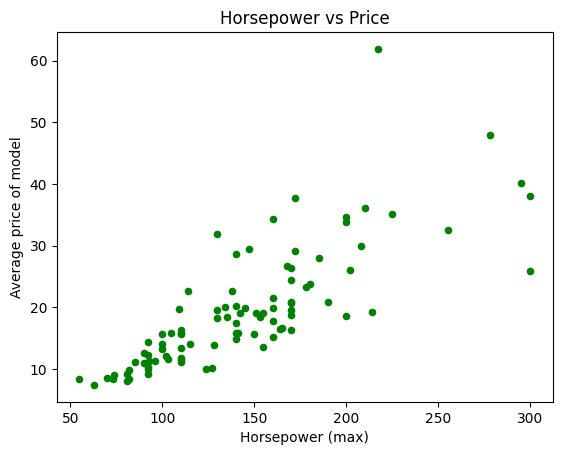

In [10]:
# Plot a bar chart showing the number of models in each airbag category
scatter_features.plot.scatter(x='Horsepower', y='Price',
                              legend=False, title="Horsepower vs Price",
                              ylabel="Average price of model", xlabel="Horsepower (max)",
                              color='green')

matplotlib method

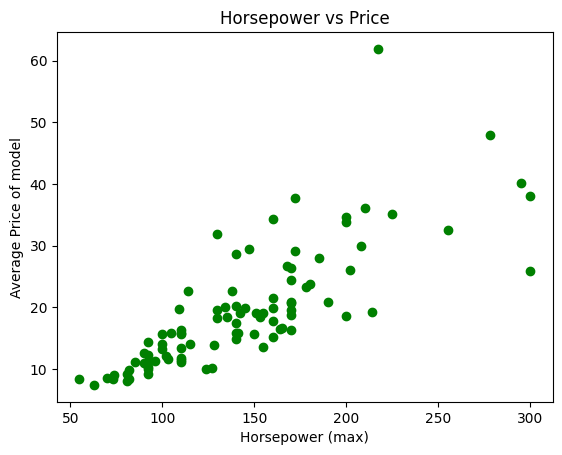

In [11]:
# Select rows from the dataframe for plotting
x = car_data['Horsepower'].values
y = car_data['Price'].values

# Create a scatterplot
plt.scatter(x, y,color = 'g')
plt.title('Horsepower vs Price')
plt.xlabel('Horsepower (max)')
plt.ylabel('Average Price of model')
plt.show()

Groupby mean: barchart

In [12]:
# Group data by 'Type'"Cars93 (1).csv"
group_by_type = car_data.groupby(by=['Type'])

# Get the mean (average) for each type across all columns
# Note the mean can only be calculated for numeric values
car_data_avg = round(group_by_type.mean(numeric_only=True), 0)
car_data_avg.sample(5)

,Min.Price,Price,Max.Price,MPG.city,MPG.highway,EngineSize,Horsepower,RPM,Rev.per.mile,Fuel.tank.capacity,Passengers,Length,Wheelbase,Width,Turn.circle,Weight
Type,,,,,,,,,,,,,,,,
Sporty,17.0,19.0,22.0,22.0,29.0,2.0,160.0,5393.0,2314.0,16.0,4.0,175.0,98.0,69.0,39.0,2900.0
Van,16.0,19.0,22.0,17.0,22.0,3.0,149.0,4744.0,2106.0,21.0,7.0,186.0,112.0,73.0,42.0,3831.0
Compact,16.0,18.0,21.0,23.0,30.0,2.0,131.0,5362.0,2476.0,16.0,5.0,182.0,103.0,67.0,38.0,2918.0
Large,23.0,24.0,26.0,18.0,27.0,4.0,179.0,4673.0,1627.0,19.0,6.0,205.0,113.0,75.0,43.0,3695.0
Midsize,24.0,27.0,30.0,20.0,27.0,3.0,173.0,5336.0,2221.0,18.0,5.0,193.0,107.0,71.0,40.0,3400.0


In [13]:
# Create a Dataframe of only the relevant features to plot
features_to_plot = pd.DataFrame({'MPG.highway': car_data_avg['MPG.highway'],
                                 'MPG.city': car_data_avg['MPG.city']})

<Axes: xlabel='Type', ylabel='Average MPG'>

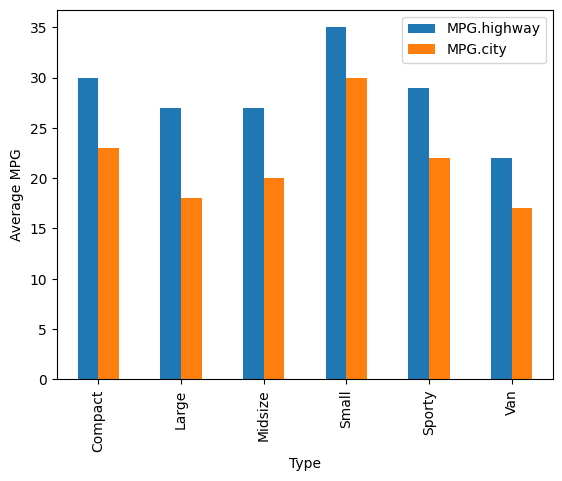

In [14]:
# Plot the average miles per gallon (MPG) for highway
# driving and city driving for each type of car
features_to_plot.plot(kind='bar', ylabel="Average MPG")

Groupby count: barchart

In [15]:
car_data['AirBags'].unique()

<StringArray>
['None', 'Driver & Passenger', 'Driver only']
Length: 3, dtype: str

In [16]:
# Group by 'Airbags' and count models in each airbag category
car_AirBagscount = car_data.groupby('AirBags').count()

# View grouped data
car_AirBagscount

,Manufacturer,Model,Type,Min.Price,Price,Max.Price,MPG.city,MPG.highway,DriveTrain,Cylinders,...,Passengers,Length,Wheelbase,Width,Turn.circle,Rear.seat.room,Luggage.room,Weight,Origin,Make
AirBags,,,,,,,,,,,,,,,,,,,,,
Driver & Passenger,16,16,16,16,16,16,16,16,16,16,...,16,16,16,16,16,16,16,16,16,16
Driver only,43,43,43,43,43,43,43,43,43,43,...,43,43,43,43,43,43,43,43,43,43
None,34,34,34,34,34,34,34,34,34,34,...,34,34,34,34,34,34,34,34,34,34


<Axes: title={'center': 'Airbag Count'}, xlabel='Airbag categories', ylabel='Number of Models'>

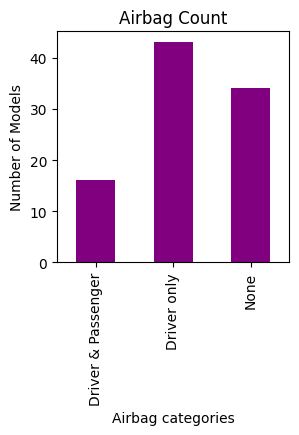

In [17]:
# Create a DataFrame with the first column and all rows
car_AirBagscount = pd.DataFrame(car_AirBagscount.iloc[:, 0])

# Rename the first column to 'Count'"Cars93 (1).csv"
car_AirBagscount.plot.bar(figsize=(3, 3), legend=False, title="Airbag Count",
                          ylabel="Number of Models", xlabel="Airbag categories",
                          color='purple')